# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = 1920 * 1080 * 3 * 1 / 1024**2          # W x H x C x B (B = 1 byte per channel)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 3600                   # f x T

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = frame_mb * 1024**2 * frames_per_day * 400 / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_bytes = 640 * 360 * 3
fleet_tb_small = small_frame_bytes * (10 * 24 * 3600) * 400 / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ **Spatial:** only ~11% of the pixels survive (1080p → 360p), and interpolation cannot invent detail that was never stored. Fine details such as a licence plate, a face, or a logo on clothing would be blurred into a few pixels and could never be recovered, however the image is later upscaled. **Temporal:** at 10 fps, consecutive frames are 100 ms apart instead of 33 ms, so fast motion (a person sprinting, a car swerving, a hand reaching or throwing) jumps a long way between frames. The correspondence problem gets harder because the same object can no longer be matched reliably from frame to frame, and brief events such as a single-frame flash, a punch or an object being dropped can fall entirely between two stored frames and vanish. Dropped frames are gone permanently.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

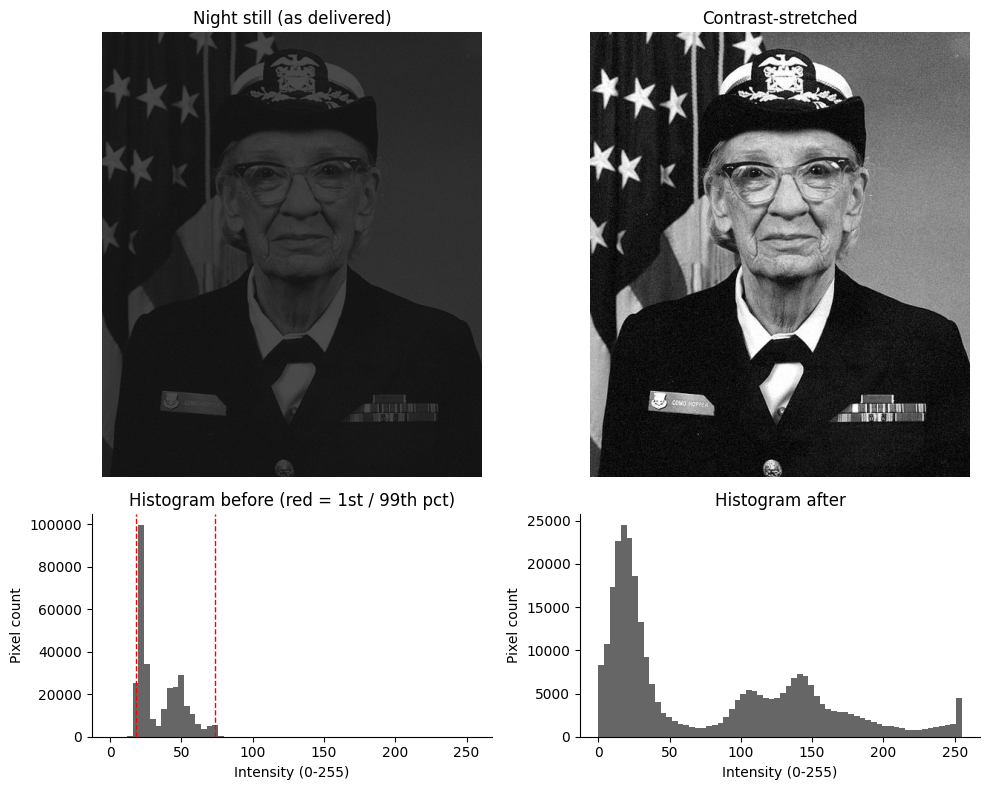

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

s1, s99 = np.percentile(stretched, [1, 99])
c_after = michelson(s99, s1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255); axes[0, 0].set_title("Night still (as delivered)")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255);   axes[0, 1].set_title("Contrast-stretched")
for a in axes[0]: a.axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="0.4")
axes[1, 0].axvline(p1, color="r", ls="--", lw=1); axes[1, 0].axvline(p99, color="r", ls="--", lw=1)
axes[1, 0].set_title("Histogram before (red = 1st / 99th pct)")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="0.4")
axes[1, 1].set_title("Histogram after")
for a in axes[1]: a.set_xlabel("Intensity (0-255)"); a.set_ylabel("Pixel count")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The histogram is a narrow, left-shifted, **dark / under-exposed, low-contrast** distribution (two clusters, a big peak near 20 and a smaller one near 50). All the pixels are crowded into roughly the 18–75 intensity range and the right three-quarters of the 0–255 axis is empty. The robust Michelson contrast comes out at about 0.61 (the 18-level black offset keeps L_min above 0), but the image uses only about a fifth of the available dynamic range, so it looks murky. Stretching linearly remaps that occupied range onto the full 0–255 range, so differences between neighbouring grey levels that were too small for the eye to see become large. The ordering of pixels is unchanged and no new detail was created; the information was already there, just displayed in a range our perception cannot separate. A histogram only counts how many pixels have each intensity and throws away *where* they are, so very different pictures (a face, a shuffled copy of the same pixels, noise with the same distribution) can share an identical histogram. It can diagnose the exposure problem but never tell you what is in the scene.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.7 s -> 78.1 s
Running : 78.6 s -> 86.0 s
Audio event   : frame 2250 (75.00 s)
Lighting event: frame 3000 (100.00 s)


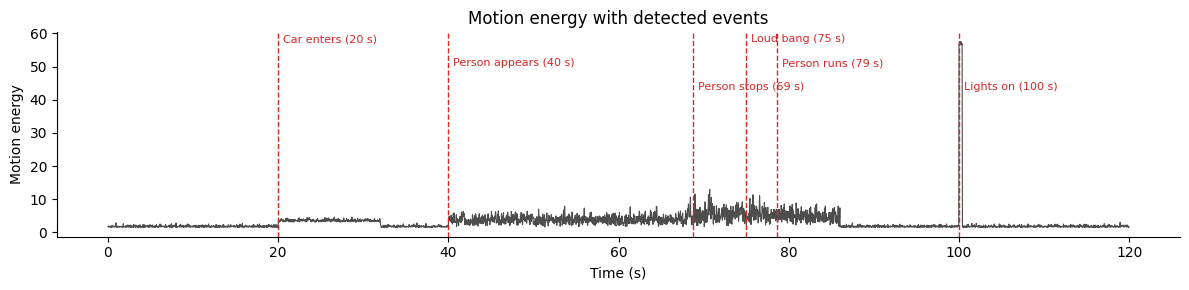

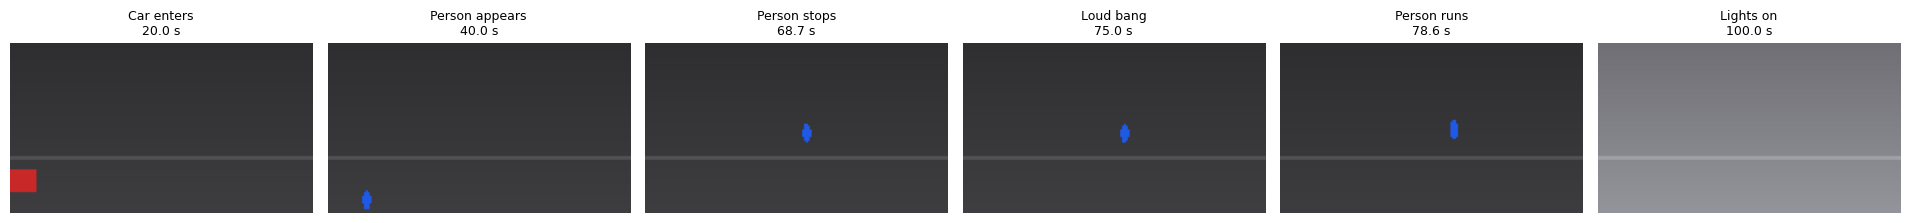

In [4]:
# TODO 1: person speed (px/s) - 1-second window: diff(FPS) on x and y, frames are 1/FPS s apart
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))   # px per 1 s = px/s
t = cctv.time_s.values

# TODO 2: standing / running time ranges (print the first and last time of each)
def ranges(mask, min_len_s=2.0, max_gap_s=1.0):
    """Contiguous True runs; gaps shorter than max_gap_s are bridged (tracking jitter), short runs dropped."""
    idx = np.where(mask)[0]
    if idx.size == 0: return []
    runs = np.split(idx, np.where(np.diff(idx) > max_gap_s * FPS)[0] + 1)
    return [(t[r[0]], t[r[-1]]) for r in runs if t[r[-1]] - t[r[0]] >= min_len_s]

stand = ranges((speed < 3).values)
run = ranges((speed > 25).values)
for s0, s1_ in stand: print(f"Standing: {s0:.1f} s -> {s1_:.1f} s")
for r0, r1 in run:    print(f"Running : {r0:.1f} s -> {r1:.1f} s")

# TODO 3: event frame indices
audio_event_idx = int(np.argmax(cctv.audio_level_db.values > -20))                 # first frame above -20 dB
lighting_event_idx = int(np.argmax(cctv.mean_brightness.diff().abs().values > 40))  # first one-frame jump > 40
print(f"Audio event   : frame {audio_event_idx} ({t[audio_event_idx]:.2f} s)")
print(f"Lighting event: frame {lighting_event_idx} ({t[lighting_event_idx]:.2f} s)")

# car arrival / person first appearance give the other moments that matter
car_idx = int(cctv.car_x.first_valid_index()); person_idx = int(cctv.person_x.first_valid_index())
events = [(car_idx, "Car enters"), (person_idx, "Person appears"),
          (int(t.searchsorted(stand[0][0]) if stand else 0), "Person stops"),
          (audio_event_idx, "Loud bang"),
          (int(t.searchsorted(run[0][0])) if run else 0, "Person runs"),
          (lighting_event_idx, "Lights on")]
events = sorted(set(events))

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, cctv.motion_energy, lw=0.8, color="0.3")
for k, (i, lab) in enumerate(events):
    ax.axvline(t[i], color="C3", ls="--", lw=1)
    ax.text(t[i] + 0.6, ax.get_ylim()[1] * (0.95 - 0.12 * (k % 3)), f"{lab} ({t[i]:.0f} s)", fontsize=8, color="C3")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy"); ax.set_title("Motion energy with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(3.2 * len(events), 2.4))
for ax, (i, lab) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i])); ax.set_title(f"{lab}\n{t[i]:.1f} s", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ The brief events are the ones at risk: the bang at 75 s (it lasts well under half a second in the audio and the person is just standing there), the moment the person stops at about 69 s, and the lights coming on at 100 s (although the brightness change then persists for the rest of the clip, so a later sample would show the *result* but not the moment it happened). A grid of frames at 0, 20, 40, 60, 80, 100 s samples time blindly, so it only catches an event if it happens to fall on a grid point; with sparse activity most of the grid frames would also be near-duplicates of an empty lot. The approach I used picks frames from **changes in the content** (motion energy, audio level, brightness jump), which is **content-based keyframe selection** (event-driven rather than uniform sampling), so each keyframe is chosen because something happened there.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

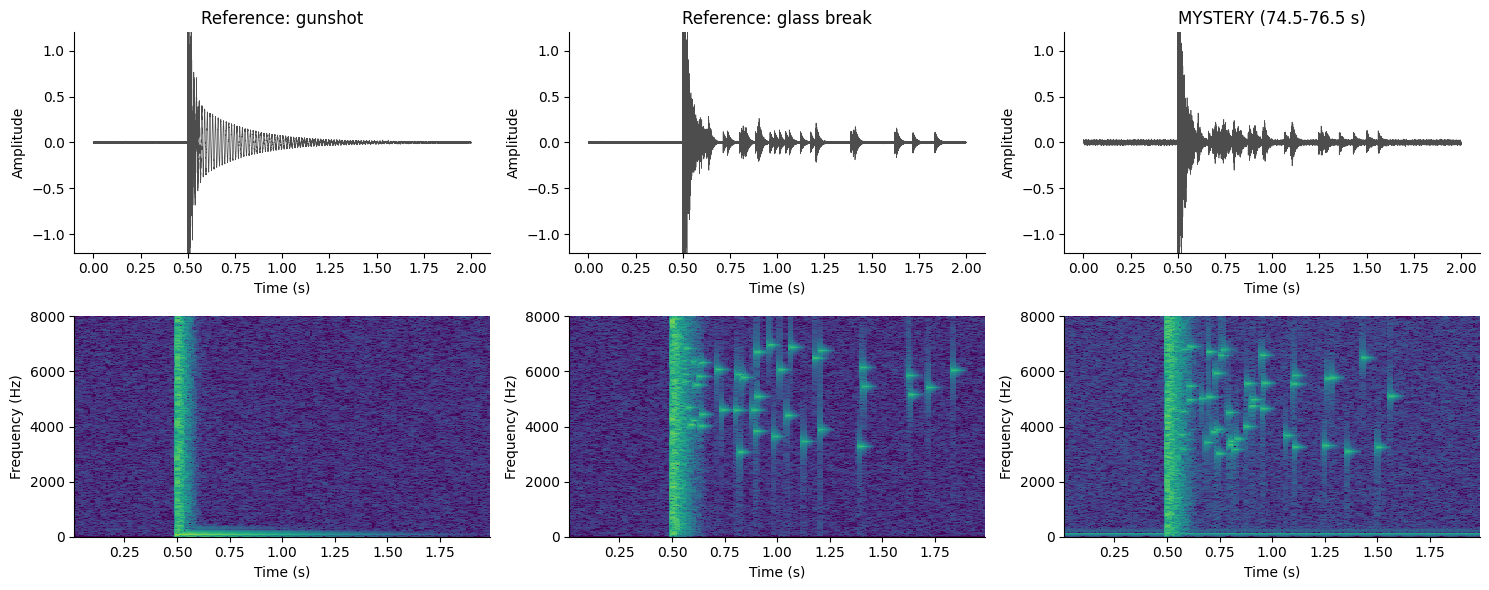

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
Verdict: mystery sound matches the GLASS BREAK signature (87% of post-impact energy above 3 kHz vs 0% for a gunshot and 99% for glass).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
tt = np.arange(int(2.0 * FS)) / FS
for k, (name, x) in enumerate(clips.items()):
    axes[0, k].plot(tt, x, lw=0.5, color="0.3"); axes[0, k].set_title(name)
    axes[0, k].set_xlabel("Time (s)"); axes[0, k].set_ylabel("Amplitude"); axes[0, k].set_ylim(-1.2, 1.2)
    f, ts, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, k].pcolormesh(ts, f, 10 * np.log10(S + 1e-12), shading="auto", vmin=-100, vmax=-20)
    axes[1, k].set_ylim(0, 8000); axes[1, k].set_xlabel("Time (s)"); axes[1, k].set_ylabel("Frequency (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    f, ts, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    win = (ts >= 0.5 + 0.2) & (ts <= 0.5 + 1.2)
    hf_fraction[name] = float(S[f > 3000][:, win].sum() / S[:, win].sum())

print({k: round(v, 3) for k, v in hf_fraction.items()})
# TODO 4: verdict
closest = min(["Reference: gunshot", "Reference: glass break"], key=lambda k: abs(hf_fraction[k] - hf_fraction["MYSTERY (74.5-76.5 s)"]))
print(f"Verdict: mystery sound matches the {closest.split(': ')[1].upper()} signature "
      f"({hf_fraction['MYSTERY (74.5-76.5 s)']:.0%} of post-impact energy above 3 kHz vs "
      f"{hf_fraction['Reference: gunshot']:.0%} for a gunshot and {hf_fraction['Reference: glass break']:.0%} for glass).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ No. In the waveforms all three clips look alike: a quiet floor, a large spike at about 0.5 s, then a decaying tail, so the waveform only says *when* something loud happened. The spectrogram adds the other two dimensions on top of **time**: **frequency** (y-axis) and **magnitude/intensity** (colour). This shows *what the energy is made of* and how it evolves. The pattern that decided it is the **scattered high-frequency specks** (the lingering 3–7 kHz tinkle of falling glass pieces) after the initial impact. A gunshot instead shows a sharp **vertical stripe** (broadband crack) plus a low horizontal band near 70 Hz from the boom, and then silence. The mystery clip shows the speckled glass pattern, with a much higher fraction of energy above 3 kHz after the impact than the gunshot, so it is **breaking glass**.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

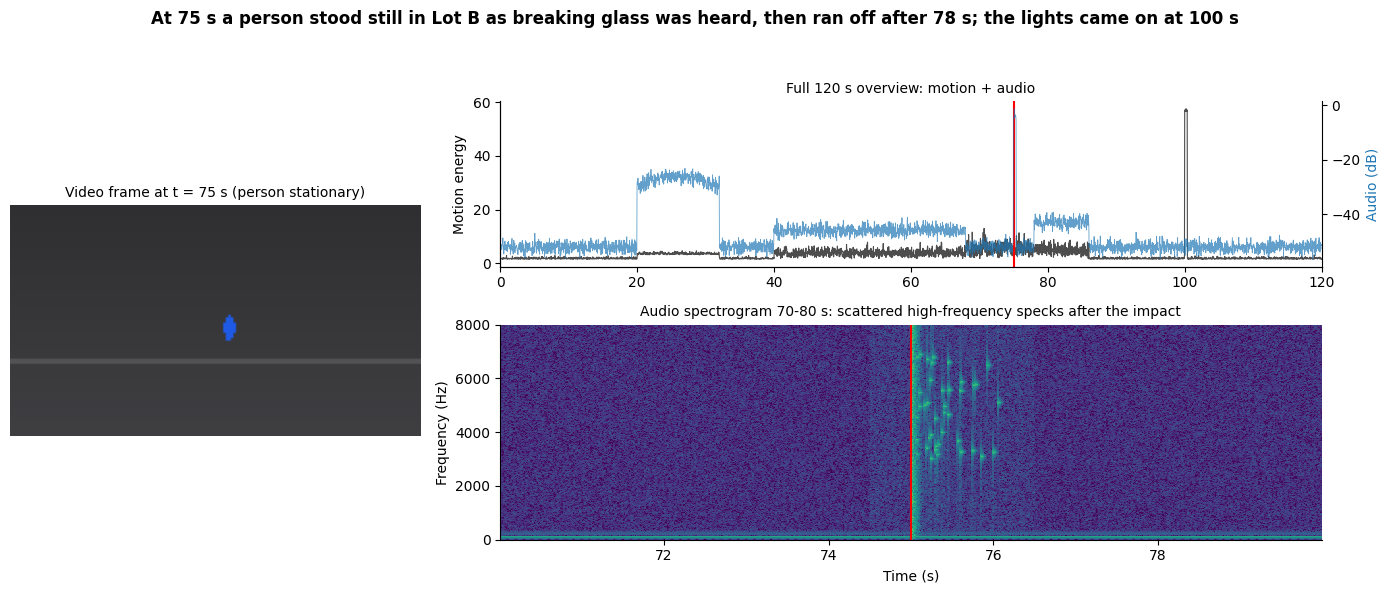

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
tt = cctv.time_s.values

# 1. video frame at t_sel (left, spans both rows)
ax_v = fig.add_subplot(gs[:, 0])
ax_v.imshow(render_frame(cctv.iloc[int(round(t_sel * FPS))])); ax_v.axis("off")
ax_v.set_title(f"Video frame at t = {t_sel:.0f} s (person stationary)", fontsize=10)

# 2. motion + audio timeline with marker (top right)
ax_t = fig.add_subplot(gs[0, 1])
ax_t.plot(tt, cctv.motion_energy, color="0.3", lw=0.8, label="Motion energy")
ax_t.set_ylabel("Motion energy"); ax_t.set_xlim(0, 120)
ax_a = ax_t.twinx(); ax_a.plot(tt, cctv.audio_level_db, color="C0", lw=0.6, alpha=0.7, label="Audio level (dB)")
ax_a.set_ylabel("Audio (dB)", color="C0"); ax_a.spines["right"].set_visible(True)
ax_t.axvline(t_sel, color="red", lw=1.5)
ax_t.set_title("Full 120 s overview: motion + audio", fontsize=10)

# 3. spectrogram 70-80 s with same marker (bottom right)
ax_s = fig.add_subplot(gs[1, 1])
seg = (t_audio >= 70) & (t_audio < 80)
f, ts, S = signal.spectrogram(x_audio[seg], fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(ts + 70, f, 10 * np.log10(S + 1e-12), shading="auto", vmin=-100, vmax=-20)
ax_s.set_ylim(0, 8000); ax_s.set_xlabel("Time (s)"); ax_s.set_ylabel("Frequency (Hz)")
ax_s.axvline(t_sel, color="red", lw=1.5)
ax_s.set_title("Audio spectrogram 70-80 s: scattered high-frequency specks after the impact", fontsize=10)

# 4. conclusion-style title
fig.suptitle("At 75 s a person stood still in Lot B as breaking glass was heard, then ran off after 78 s; the lights came on at 100 s",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_ The bang would be placed at 77 s instead of 75 s (or the video 2 s early), so the briefing would claim the person *reacted before* the sound or was already running when the glass broke. That changes the story (a startled bystander vs. someone who caused the break and fled) and the response taken. The **top-right timeline** would expose it: the audio spike would no longer line up with the motion-energy change, and the red marker at 75 s would sit on silence, while the **spectrogram** panel would show its burst of high-frequency specks not under the marker. The video frame panel alone would show nothing wrong, which is why the shared time marker across panels matters.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ A car crossed Lot B at about 20–32 s, a person entered at 40 s, stood still from about 69 s, and at 75 s a loud bang occurred that the spectrogram identifies as **breaking glass, not a gunshot**; the person then ran from about 79 s until leaving at 86 s, and the lights came on at 100 s. I would lead with the **synchronized view**, because it takes the audience from overview (the 120 s timeline) to the selected moment (frame plus spectrogram) and shows the sound (time × frequency × magnitude) and the picture at the same timestamp, so the claim "glass, not gunshot" is backed by two modalities. Content-based keyframes then let you review the incident without watching two minutes of video. Storing all 400 cameras at 1080p/30 fps uncompressed would take about 5,866 TB/day against about 217 TB/day at 360p/10 fps (11% of the pixels), so I recommend a tiered policy: low-resolution continuous recording, with full-quality capture triggered by motion or audio events. Whatever is cut, it must not sacrifice the temporal resolution (frame rate) and detail around events, because fast action and fine detail such as a face or plate cannot be recovered once discarded. Night cameras should also get a contrast stretch (or better exposure) before anyone interprets them.